# Electricity forecasting with more input features

The first comparison used hourly demand alone: 168 past hours to predict the next
24 hours. This notebook keeps that task and adds the other measurements supplied
by the dataset, calendar features, and summaries of the observed week.

We rerun the nine neural models and add a CatBoost baseline. Each expanded-input
model receives the same information. The original demand-only scores are retained
for comparison; an option below reruns those neural models too.

**Use:** Open this file in Jupyter, install the dependencies if needed, and run
the cells in order. The processed CSV is embedded, so the notebook runs on its own.
Saved outputs contain an actual CPU run. Runtime is omitted from the comparison;
`REPORT_TIMING = True` measures it on the machine executing the notebook.

## Data and what is available at forecast time

Source: [UCI Individual Household Electric Power Consumption, ID 235](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption).
Hebrail, G. & Berard, A. (2006), [DOI 10.24432/C58K54](https://doi.org/10.24432/C58K54),
licensed [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/).
This is one household in Sceaux, France, with 2,075,259 minute records.

| Historical measurement | Meaning / stored hourly unit |
|---|---|
| `demand_kw` | Active power, kW; also the forecast target |
| `reactive_power_kvar` | Reactive power, unchanged source scale |
| `voltage_v` | Voltage, V |
| `current_a` | Current intensity, A |
| `sub_metering_1_wh_per_minute` | Kitchen submeter, mean Wh per recorded minute |
| `sub_metering_2_wh_per_minute` | Laundry submeter, mean Wh per recorded minute |
| `sub_metering_3_wh_per_minute` | Water heater / air conditioner submeter, mean Wh per recorded minute |

Every channel is resampled to the hourly mean of available minutes. Completely
empty hours are forward-filled separately for each channel. Submeter means are
kept as mean Wh/minute; they are not presented as hourly energy totals. The CSV
also stores observation counts and imputation flags for auditing and scoring.
Those audit columns are not model inputs.

At origin `t`, inputs contain measurements from `[t-168, t)`, calendar values for
those hours and for `[t, t+24)`, and eight demand summaries of `[t-168, t)`.
Future measured voltage, current, power, and submeter readings are never supplied.
Each historical hour is treated as available after that hour has ended; a real
deployment would need to account for its meter's reporting delay.

## Running on Mac, CPU, GPU, or TPU

Leave `REQUESTED_DEVICE = "auto"` for normal use, or choose a backend explicitly.
All model tensors use float32; the float64 metric calculations stay in NumPy on CPU.

| Environment | Device option | Setup |
|---|---|---|
| Intel Mac / Linux / Windows CPU | `cpu` or `auto` | Standard compatible PyTorch build |
| Apple silicon Mac | `mps` or `auto` | macOS/PyTorch with MPS support; unsupported MPS operators may fall back to CPU |
| NVIDIA GPU | `cuda` or `auto` | PyTorch CUDA build and working driver |
| AMD GPU | `cuda` or `auto` | Supported ROCm build; PyTorch uses the CUDA API name for ROCm |
| Intel GPU | `xpu` or `auto` | PyTorch XPU build and working runtime |
| Cloud TPU, native backend | `tpu` (or detected by `auto`) | Install `torch_tpu` on a TPU host and restart the kernel |
| Existing TPU/XLA environment | `xla` | Matching `torch` / `torch_xla[tpu]` versions; explicit lazy optimizer steps are included |

This notebook uses one selected device. Distributed multi-GPU or TPU-pod training
is not configured. GPU and TPU availability depends on the installed backend and
hardware. The preflight cell checks a forward pass, backward pass, and optimizer
step for every model before the full run. In `auto` mode, an unsupported accelerator
operator triggers a clearly reported CPU fallback for the entire comparison.

The displayed benchmark was executed on CPU. The portability update was checked
with a separate CPU smoke test; no Mac GPU, CUDA, ROCm, XPU, or TPU hardware was
available for verification here. If memory is limited, lower `BATCH_SIZE`, for
example to 64. Restart the kernel after changing packages or MPS fallback settings.

Setup references: [PyTorch installer](https://pytorch.org/get-started/locally/),
[MPS](https://docs.pytorch.org/docs/stable/notes/mps.html),
[ROCm](https://docs.pytorch.org/docs/stable/notes/hip.html),
[Intel XPU](https://docs.pytorch.org/docs/stable/xpu.html),
[native TorchTPU](https://docs.cloud.google.com/tpu/docs/pytorch-on-tpu).
TorchTPU is the current TPU path; XLA is retained for existing environments.

The nine neural models use the selected PyTorch device. **CatBoost uses CPU on
every platform** in this notebook, including Mac and TPU environments. Its inputs
are the same numbers flattened into columns. CPU has been executed here; accelerator
support uses the device preflight below and has not been validated on physical
Mac/GPU/TPU hardware in this run. This is a single-device notebook.

In [1]:
# Install in this notebook's kernel if needed, then restart it.
# %pip install numpy pandas matplotlib torch catboost jupyterlab
# On a CUDA/ROCm/XPU host, use the PyTorch build appropriate to the device.
# Native Cloud TPU: install its supported torch / torch_tpu environment first.
# Legacy XLA: use matching torch and torch_xla[tpu] versions, then REQUESTED_DEVICE="xla".
# CatBoost is optional only if RUN_CATBOOST=False in the next cell.


In [2]:
import base64
import copy
import gc
import gzip
import hashlib
import io
import json
import math
import os
import platform
import subprocess
import random
import time
import urllib.request
import zipfile
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")  # Set before importing torch.
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader
from IPython.display import display

SOURCE_MODE = "bundled"  # "uci" rebuilds all seven measurements from the source.
DATA_URL = ""  # Optional public GitHub Raw URL for electricity_hourly_multifeature.csv.
FEATURE_SET = "all"  # "all" or "demand"; demand reproduces the original input contract.
RUN_UNIVARIATE_NEURAL = False  # True also reruns the nine original neural configurations.
RUN_CATBOOST = True
CATBOOST_ITERATIONS = 300
CATBOOST_PATIENCE = 40
LOOKBACK = 168
HORIZON = 24
SEED = 42
BATCH_SIZE = 256
MAX_EPOCHS = 15
PATIENCE = 3
LEARNING_RATE = 1e-3
WEIGHT_DECAY = 1e-4
REPORT_TIMING = False  # Set True to measure/report fit time on your own hardware.
MODEL_NAMES = ["Linear", "MLP", "GRU", "LSTM", "CNN1D", "TCN",
               "Patch Transformer", "N-BEATS-style", "Transformer"]
REQUESTED_DEVICE = "auto"  # auto / cpu / cuda / mps / xpu / tpu / xla; cuda:1 also works.
torch_xla = xm = None

def select_device(requested="auto"):
    global torch_xla, xm
    requested = requested.lower()
    if requested == "auto":
        if torch.cuda.is_available():
            return torch.device("cuda")  # NVIDIA CUDA or AMD ROCm PyTorch build.
        if hasattr(torch, "xpu") and torch.xpu.is_available():
            return torch.device("xpu")
        if hasattr(torch.backends, "mps") and torch.backends.mps.is_available():
            return torch.device("mps")
        if hasattr(torch, "accelerator") and torch.accelerator.is_available():
            accelerator = torch.accelerator.current_accelerator()
            if accelerator is not None and accelerator.type == "tpu":
                return torch.device("tpu")
        return torch.device("cpu")
    if requested in ("tpu", "xla"):
        if requested == "tpu":
            try:
                import torch_tpu  # Optional native TPU backend; installed only on a TPU host.
            except ImportError as error:
                raise RuntimeError("Install torch_tpu on a Cloud TPU host, restart the kernel, "
                                   "and select REQUESTED_DEVICE='tpu'.") from error
            return torch.device("tpu")
        os.environ.setdefault("PJRT_DEVICE", "TPU")
        try:
            import torch_xla
            import torch_xla.core.xla_model as xm
        except ImportError as error:
            raise RuntimeError("For legacy TPU/XLA, install matching torch and torch_xla[tpu] "
                               "versions in a separate TPU environment and restart.") from error
        return torch_xla.device() if hasattr(torch_xla, "device") else xm.xla_device()
    kind = requested.split(":")[0]
    available = {"cpu": True, "cuda": torch.cuda.is_available(),
                 "mps": hasattr(torch.backends, "mps") and torch.backends.mps.is_available(),
                 "xpu": hasattr(torch, "xpu") and torch.xpu.is_available()}
    if kind not in available or not available[kind]:
        raise RuntimeError(f"Device {requested!r} is unavailable in this PyTorch installation. "
                           "Use 'auto'/'cpu' or install the build for your hardware.")
    return torch.device(requested)

DEVICE = select_device(REQUESTED_DEVICE)

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)
    elif DEVICE.type == "mps":
        torch.mps.synchronize()
    elif DEVICE.type == "xpu":
        torch.xpu.synchronize(DEVICE)
    elif DEVICE.type == "tpu":
        if hasattr(torch, "accelerator") and hasattr(torch.accelerator, "synchronize"):
            torch.accelerator.synchronize()
        else:
            torch.tpu.synchronize()
    elif DEVICE.type == "xla":
        if hasattr(torch_xla, "sync"):
            torch_xla.sync(wait=True)
        else:
            xm.mark_step()
            xm.wait_device_ops()

def optimizer_step(optimizer):
    optimizer.step()
    if DEVICE.type == "xla":
        # XLA is lazy; materialize each optimizer update explicitly.
        if hasattr(torch_xla, "sync"):
            torch_xla.sync()
        else:
            xm.mark_step()

def clear_device_cache():
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    elif DEVICE.type == "mps":
        torch.mps.empty_cache()
    elif DEVICE.type == "xpu" and hasattr(torch.xpu, "empty_cache"):
        torch.xpu.empty_cache()
torch.set_num_threads(min(4, os.cpu_count() or 1))
OUTPUT_DIR = Path("outputs_multifeature" if FEATURE_SET == "all" else "outputs_demand")
OUTPUT_DIR.mkdir(exist_ok=True)
(OUTPUT_DIR / "weights").mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False
    if DEVICE.type == "mps":
        torch.mps.manual_seed(seed)
    elif DEVICE.type == "xpu":
        torch.xpu.manual_seed_all(seed)
    elif DEVICE.type == "tpu":
        torch.tpu.manual_seed_all(seed)
    elif DEVICE.type == "xla":
        xm.set_rng_state(seed, str(DEVICE))

def hardware_summary():
    system = platform.system()
    processor = platform.processor() or platform.machine()
    if system == "Darwin":
        try:
            probe = subprocess.run(["sysctl", "-n", "machdep.cpu.brand_string"],
                capture_output=True, text=True, check=False, timeout=5)
            processor = probe.stdout.strip() or processor
        except (OSError, subprocess.SubprocessError):
            pass
    accelerator = "CPU"
    if DEVICE.type == "cuda":
        accelerator = torch.cuda.get_device_name(DEVICE)
    elif DEVICE.type == "mps":
        accelerator = f"Apple Metal / {processor}"
    elif DEVICE.type == "xpu":
        accelerator = torch.xpu.get_device_name(DEVICE)
    elif DEVICE.type in ("tpu", "xla"):
        accelerator = f"TPU backend ({DEVICE.type})"
    return {"operating_system": "macOS" if system == "Darwin" else system,
            "os_version": platform.mac_ver()[0] if system == "Darwin" else platform.release(),
            "architecture": platform.machine(), "processor": processor,
            "device": str(DEVICE), "accelerator": accelerator,
            "torch_version": torch.__version__, "cpu_threads": torch.get_num_threads(),
            "dtype": "float32", "batch_size": BATCH_SIZE,
            "mps_cpu_fallback_enabled": DEVICE.type == "mps" and
                os.environ.get("PYTORCH_ENABLE_MPS_FALLBACK") == "1"}

def write_local_timing_report(results):
    if not REPORT_TIMING:
        return
    local = results.loc[results["kind"] == "Learned",
        ["model", "training_seconds", "epochs_run", "best_epoch"]].copy()
    local = local.rename(columns={"training_seconds": "fit_wall_seconds"})
    hardware = hardware_summary()
    local["device"] = results.loc[local.index, "device"].values
    for key in ("operating_system", "batch_size"):
        local[key] = hardware[key]
    local["accelerator"] = ["CPU (CatBoost)" if name.startswith("CatBoost") else
                            hardware["accelerator"] for name in local["model"]]
    local.to_csv(OUTPUT_DIR / "local_timing.csv", index=False)
    details = {"recorded_utc": datetime.now(timezone.utc).isoformat(),
        "hardware": hardware,
        "timing_scope": "training + validation + checkpoint and history writes",
        "excluded": "model initialization, best-checkpoint restore, final test prediction",
        "first_use_compilation": "included when required by the selected backend",
        "synchronization": "selected accelerator synchronized before and after the fit loop",
        "interpretation": "local diagnostics; no comparison across different machines"}
    (OUTPUT_DIR / "local_timing_metadata.json").write_text(json.dumps(details, indent=2))
    print("Local fit times on this machine (training + validation + checkpoint writes):")
    display(local.round({"fit_wall_seconds": 2}))
    print(json.dumps(hardware, indent=2))

seed_everything()
environment = {"python": platform.python_version(), "numpy": np.__version__,
               "pandas": pd.__version__, "torch": torch.__version__,
               "matplotlib": matplotlib.__version__, "device": str(DEVICE),
               "cpu_threads": torch.get_num_threads(), "requested_device": REQUESTED_DEVICE,
               "hip_version": getattr(torch.version, "hip", None)}
print(json.dumps(environment, indent=2))
assert FEATURE_SET in ("all", "demand")


{
  "python": "3.13.9",
  "numpy": "2.5.2",
  "pandas": "3.0.5",
  "torch": "2.12.0",
  "matplotlib": "3.11.1",
  "device": "mps",
  "cpu_threads": 4,
  "requested_device": "auto",
  "hip_version": null
}


The collapsed cell stores only the compressed CSV. The following cell contains the readable loading and source-preprocessing code.

In [3]:
EMBEDDED_MULTIFEATURE_CSV_GZIP_BASE64 = '...'


In [4]:
DATASET_PAGE = "https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption"
RAW_URL = "https://archive.ics.uci.edu/static/public/235/individual+household+electric+power+consumption.zip"
RAW_ZIP_SHA256 = "9f84b46ade8a2d8e1286ec4b2b6c2987a45a755c59f263be3b3b3d10dfbda3ff"
HOURLY_CSV_SHA256 = "9c3ccfeca53444126550867208723c4c1965a973fd290a34d2c9d2b8aba669a8"
MEASUREMENT_MAP = {
    "Global_active_power": "demand_kw", "Global_reactive_power": "reactive_power_kvar",
    "Voltage": "voltage_v", "Global_intensity": "current_a",
    "Sub_metering_1": "sub_metering_1_wh_per_minute",
    "Sub_metering_2": "sub_metering_2_wh_per_minute",
    "Sub_metering_3": "sub_metering_3_wh_per_minute",
}
MEASUREMENT_COLUMNS = list(MEASUREMENT_MAP.values())
DATA_DIR, CACHE_DIR = Path("data"), Path(".cache")
DATA_DIR.mkdir(exist_ok=True)
CACHE_DIR.mkdir(exist_ok=True)
HOURLY_CSV = DATA_DIR / "electricity_hourly_multifeature.csv"

def sha256_bytes(content):
    return hashlib.sha256(content).hexdigest()

def rebuild_hourly_from_uci():
    archive = CACHE_DIR / "household_power_consumption.zip"
    if not archive.exists():
        print("Downloading the official UCI archive:", RAW_URL)
        temporary = archive.with_suffix(".zip.part")
        urllib.request.urlretrieve(RAW_URL, temporary)
        temporary.replace(archive)
    content = archive.read_bytes()
    if sha256_bytes(content) != RAW_ZIP_SHA256:
        raise ValueError("UCI archive checksum changed. Inspect the source before proceeding.")
    with zipfile.ZipFile(io.BytesIO(content)) as archive:
        with archive.open("household_power_consumption.txt") as f:
            minute = pd.read_csv(f, sep=";", na_values=["?"])
    timestamps = pd.to_datetime(minute.pop("Date") + " " + minute.pop("Time"),
                                 format="%d/%m/%Y %H:%M:%S")
    minute.index = timestamps
    minute = minute.rename(columns=MEASUREMENT_MAP)
    assert minute.index.is_unique and minute.index.is_monotonic_increasing
    means = minute.resample("h").mean()
    hourly = means.ffill()
    hourly["demand_kw_observed"] = means["demand_kw"]
    hourly["valid_minutes"] = minute["demand_kw"].resample("h").count()
    hourly["recorded_minutes"] = minute["demand_kw"].resample("h").size()
    for column in MEASUREMENT_COLUMNS:
        hourly[column + "_was_imputed"] = means[column].isna()
    hourly.index.name = "timestamp"
    assert hourly[MEASUREMENT_COLUMNS].notna().all().all()
    return hourly.to_csv(float_format="%.10g").encode("utf-8")

if DATA_URL.strip():
    # Use a public Raw URL, for example:
    # https://raw.githubusercontent.com/OWNER/REPO/main/data/electricity_hourly_multifeature.csv
    with urllib.request.urlopen(DATA_URL, timeout=120) as response:
        csv_content = response.read()
elif SOURCE_MODE == "uci":
    csv_content = rebuild_hourly_from_uci()
elif SOURCE_MODE == "bundled":
    csv_content = (HOURLY_CSV.read_bytes() if HOURLY_CSV.exists() else
        gzip.decompress(base64.b64decode(EMBEDDED_MULTIFEATURE_CSV_GZIP_BASE64)))
else:
    raise ValueError("SOURCE_MODE must be 'bundled' or 'uci'.")
if sha256_bytes(csv_content) != HOURLY_CSV_SHA256:
    raise ValueError("CSV checksum differs. Use the supplied multifeature CSV without edits.")
HOURLY_CSV.write_bytes(csv_content)
hourly = pd.read_csv(io.BytesIO(csv_content), parse_dates=["timestamp"]).set_index("timestamp")
assert len(hourly) == 34589
assert hourly.index.is_unique and hourly.index.is_monotonic_increasing
assert (hourly.index.to_series().diff().dropna() == pd.Timedelta(hours=1)).all()
assert hourly[MEASUREMENT_COLUMNS].notna().all().all()
assert np.allclose(hourly["demand_kw"], hourly["demand_kw_observed"].ffill())
audit = {"dataset": DATASET_PAGE, "raw_download": RAW_URL, "doi": "10.24432/C58K54",
    "license": "CC BY 4.0", "raw_zip_sha256": RAW_ZIP_SHA256,
    "hourly_csv_sha256": HOURLY_CSV_SHA256, "raw_rows": 2075259,
    "hourly_rows": len(hourly), "first_hour": str(hourly.index[0]),
    "last_hour": str(hourly.index[-1]),
    "imputed_hours_by_measurement": {c: int(hourly[c + "_was_imputed"].sum())
                                     for c in MEASUREMENT_COLUMNS},
    "timestamp_convention": "naive source local clock; interval start",
    "preprocessing": "hourly mean of available minutes; forward fill empty hours per channel"}
(DATA_DIR / "source_metadata_multifeature.json").write_text(json.dumps(audit, indent=2))
display(hourly[MEASUREMENT_COLUMNS].head())
print("Hourly rows:", len(hourly), "| demand hours filled:",
      audit["imputed_hours_by_measurement"]["demand_kw"])
print("CSV SHA-256:", HOURLY_CSV_SHA256)


,demand_kw,reactive_power_kvar,voltage_v,current_a,sub_metering_1_wh_per_minute,sub_metering_2_wh_per_minute,sub_metering_3_wh_per_minute
timestamp,,,,,,,
2006-12-16 17:00:00,4.222889,0.229000,234.643889,18.100000,0.0,0.527778,16.861111
2006-12-16 18:00:00,3.632200,0.080033,234.580167,15.600000,0.0,6.716667,16.866667
2006-12-16 19:00:00,3.400233,0.085233,233.232500,14.503333,0.0,1.433333,16.683333
2006-12-16 20:00:00,3.268567,0.075100,234.071500,13.916667,0.0,0.000000,16.783333
2006-12-16 21:00:00,3.056467,0.076667,237.158667,13.046667,0.0,0.416667,17.216667


Hourly rows: 34589 | demand hours filled: 421
CSV SHA-256: 9c3ccfeca53444126550867208723c4c1965a973fd290a34d2c9d2b8aba669a8


## Features and chronological evaluation

| Input group | Shape for one expanded-input sample |
|---|---|
| Historical electrical measurements | 168 hours × 7 channels |
| Historical calendar | 168 hours × 7 channels |
| Future-known calendar | 24 hours × 7 channels |
| Recent demand summaries | 8 values |

Calendar channels are sine/cosine encodings for hour of day, day of week, and
position within the year, plus a weekend flag. Recent summaries are the mean,
standard deviation, minimum, and maximum over the last 24 and 168 hours. These
summaries use only the existing input window, so they add a representation of
the same demand history, without extending it.

The history tensor is `[batch, 168, 14]`; the shared context is `[batch, 176]`.
The target remains `[batch, 24]`. The context is available to every neural
forecast head and to every N-BEATS-style block; CatBoost receives the exact same
2,528 numbers as a flat row.

Train/validation/test boundaries are at 70% and 85% of the time axis. Targets
stay inside their own partition. Validation and test contexts may use earlier
history. Scaling uses only the training partition; summary scalers use only
training origins. The primary score is pooled test RMSE in kW over all origins
and horizons. An observed-only score excludes completely imputed target hours.

,origins,first_origin,last_origin,last_target
partition,,,,
Train,24021,2006-12-23 17:00:00,2009-09-19 13:00:00,2009-09-20 12:00:00
Validation,5165,2009-09-20 13:00:00,2010-04-23 17:00:00,2010-04-24 16:00:00
Test,5166,2010-04-24 17:00:00,2010-11-25 22:00:00,2010-11-26 21:00:00


History: [batch, 168, 14]; context: [batch, 176]
Train-only target scaler: mean=1.084858, std=0.926933 kW
Causal summary and train/validation/test boundary checks passed.


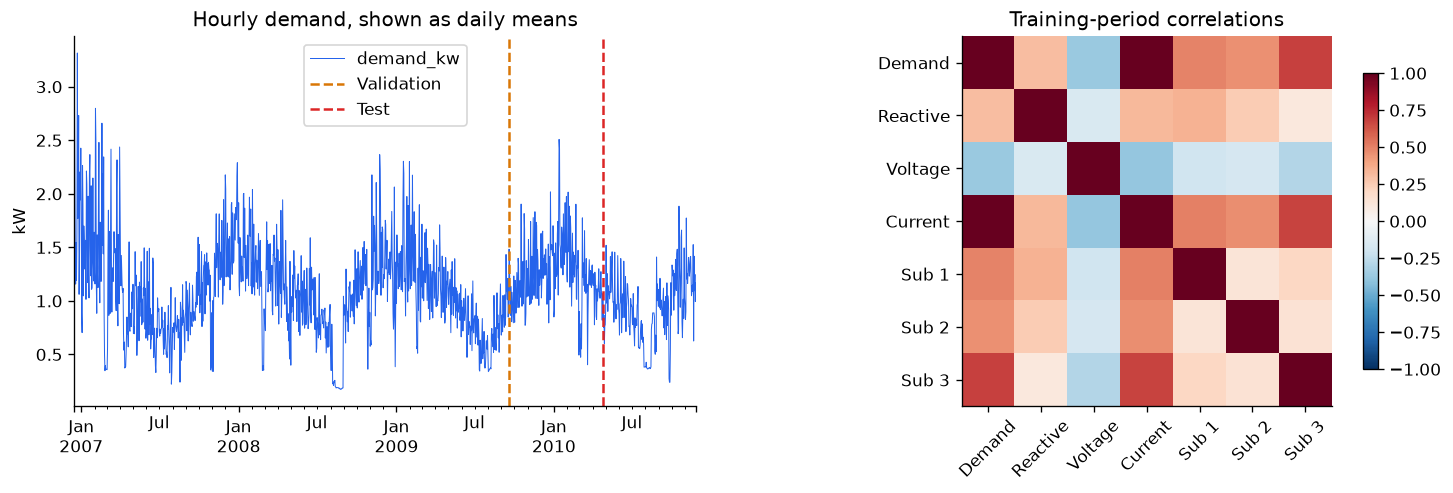

In [5]:
n = len(hourly)
train_end, val_end = int(0.70 * n), int(0.85 * n)
origin_sets = {
    "Train": np.arange(LOOKBACK, train_end - HORIZON + 1),
    "Validation": np.arange(train_end, val_end - HORIZON + 1),
    "Test": np.arange(val_end, n - HORIZON + 1),
}
for name, origins in origin_sets.items():
    assert len(origins) and origins[0] >= LOOKBACK
    assert origins[-1] + HORIZON <= {"Train": train_end, "Validation": val_end, "Test": n}[name]
assert origin_sets["Train"][-1] + HORIZON <= origin_sets["Validation"][0]
assert origin_sets["Validation"][-1] + HORIZON <= origin_sets["Test"][0]
values = hourly["demand_kw"].to_numpy(dtype=np.float64)
observed = hourly["valid_minutes"].to_numpy() > 0
train_mean, train_std = values[:train_end].mean(), values[:train_end].std(ddof=0)
z = ((values - train_mean) / train_std).astype(np.float32)

def calendar_frame(index):
    # All values are determined by the timestamp, independent of future readings.
    year_length = np.where(index.is_leap_year, 366.0, 365.0)
    year_phase = (index.dayofyear.to_numpy() - 1 + index.hour.to_numpy() / 24) / year_length
    return pd.DataFrame({
        "hour_sin": np.sin(2 * np.pi * index.hour / 24),
        "hour_cos": np.cos(2 * np.pi * index.hour / 24),
        "weekday_sin": np.sin(2 * np.pi * index.dayofweek / 7),
        "weekday_cos": np.cos(2 * np.pi * index.dayofweek / 7),
        "year_sin": np.sin(2 * np.pi * year_phase),
        "year_cos": np.cos(2 * np.pi * year_phase),
        "is_weekend": (index.dayofweek >= 5).astype(float),
    }, index=index, dtype=np.float32)

def causal_summary_frame(demand):
    # Row t summarizes readings strictly before t. No centered rolling windows.
    previous = demand.shift(1)
    result = pd.DataFrame(index=demand.index)
    for window in (24, LOOKBACK):
        rolling = previous.rolling(window, min_periods=window)
        result[f"demand_mean_{window}h"] = rolling.mean()
        result[f"demand_std_{window}h"] = rolling.std(ddof=0)
        result[f"demand_min_{window}h"] = rolling.min()
        result[f"demand_max_{window}h"] = rolling.max()
    return result

calendar = calendar_frame(hourly.index)
summaries = causal_summary_frame(hourly["demand_kw"])
measurement_mean = hourly[MEASUREMENT_COLUMNS].iloc[:train_end].mean()
measurement_std = hourly[MEASUREMENT_COLUMNS].iloc[:train_end].std(ddof=0).replace(0, 1)
summary_mean = summaries.iloc[origin_sets["Train"]].mean()
summary_std = summaries.iloc[origin_sets["Train"]].std(ddof=0).replace(0, 1)
scaled_measurements = ((hourly[MEASUREMENT_COLUMNS] - measurement_mean) /
                        measurement_std).to_numpy(dtype=np.float32)
calendar_values = calendar.to_numpy(dtype=np.float32)
scaled_summaries = ((summaries - summary_mean) / summary_std).to_numpy(dtype=np.float32)
all_history = np.concatenate([scaled_measurements, calendar_values], axis=1)

def configure_features(feature_set):
    global past_values, context_values, N_PAST, N_CONTEXT, PAST_FEATURES, CONTEXT_FEATURES
    if feature_set == "demand":
        past_values = z[:, None]
        context_values = np.empty((n, 0), dtype=np.float32)
        PAST_FEATURES, CONTEXT_FEATURES = ["demand_kw"], []
    elif feature_set == "all":
        past_values = all_history
        future_calendar = np.zeros((n, HORIZON * len(calendar.columns)), dtype=np.float32)
        for t in range(n - HORIZON + 1):
            future_calendar[t] = calendar_values[t:t+HORIZON].reshape(-1)
        context_values = np.concatenate([future_calendar, scaled_summaries], axis=1)
        PAST_FEATURES = MEASUREMENT_COLUMNS + list(calendar.columns)
        CONTEXT_FEATURES = [f"horizon_{h+1}_{c}" for h in range(HORIZON)
                            for c in calendar.columns] + list(summaries.columns)
    else:
        raise ValueError(feature_set)
    N_PAST, N_CONTEXT = past_values.shape[1], context_values.shape[1]
    for origins in origin_sets.values():
        assert np.isfinite(context_values[origins]).all()
    assert np.isfinite(past_values).all()

configure_features(FEATURE_SET)
split_table = pd.DataFrame([
    {"partition": name, "origins": len(origins), "first_origin": hourly.index[origins[0]],
     "last_origin": hourly.index[origins[-1]],
     "last_target": hourly.index[origins[-1] + HORIZON - 1]}
    for name, origins in origin_sets.items()
]).set_index("partition")
display(split_table)
print(f"History: [batch, {LOOKBACK}, {N_PAST}]; context: [batch, {N_CONTEXT}]")
print(f"Train-only target scaler: mean={train_mean:.6f}, std={train_std:.6f} kW")
scalers = {"measurement_mean": measurement_mean.to_dict(),
           "measurement_std": measurement_std.to_dict(), "summary_mean": summary_mean.to_dict(),
           "summary_std": summary_std.to_dict(), "target_mean": float(train_mean),
           "target_std": float(train_std), "past_features": PAST_FEATURES,
           "context_features": CONTEXT_FEATURES}
(OUTPUT_DIR / "feature_scalers.json").write_text(json.dumps(scalers, indent=2))

# Check a representative validation origin against direct, within-window calculations.
probe_t = int(origin_sets["Validation"][0])
probe_history = values[probe_t-LOOKBACK:probe_t]
expected = []
for window in (24, LOOKBACK):
    a = probe_history[-window:]
    expected.extend([a.mean(), a.std(ddof=0), a.min(), a.max()])
assert np.allclose(summaries.iloc[probe_t].to_numpy(), expected, atol=1e-10)
altered = hourly["demand_kw"].copy()
altered.iloc[probe_t:] += 1000
assert np.allclose(causal_summary_frame(altered).iloc[probe_t], summaries.iloc[probe_t])
print("Causal summary and train/validation/test boundary checks passed.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
hourly["demand_kw"].resample("D").mean().plot(ax=axes[0], lw=0.6, color="#2563eb")
axes[0].axvline(hourly.index[train_end], color="#d97706", ls="--", label="Validation")
axes[0].axvline(hourly.index[val_end], color="#dc2626", ls="--", label="Test")
axes[0].set(title="Hourly demand, shown as daily means", ylabel="kW", xlabel="")
axes[0].legend()
corr = hourly[MEASUREMENT_COLUMNS].iloc[:train_end].corr()
im = axes[1].imshow(corr, vmin=-1, vmax=1, cmap="RdBu_r")
short = ["Demand", "Reactive", "Voltage", "Current", "Sub 1", "Sub 2", "Sub 3"]
axes[1].set(xticks=range(7), yticks=range(7), xticklabels=short, yticklabels=short,
            title="Training-period correlations")
axes[1].tick_params(axis="x", rotation=45)
fig.colorbar(im, ax=axes[1], shrink=0.8)
fig.savefig(OUTPUT_DIR / "data_and_features.png", bbox_inches="tight")
plt.show()


In [6]:
class ForecastDataset(Dataset):
    def __init__(self, origins):
        self.past = torch.from_numpy(past_values)
        self.context = torch.from_numpy(context_values)
        self.targets = torch.from_numpy(z)
        self.origins = np.asarray(origins)

    def __len__(self):
        return len(self.origins)

    def __getitem__(self, index):
        t = int(self.origins[index])
        return self.past[t-LOOKBACK:t], self.context[t], self.targets[t:t+HORIZON]

def configure_loaders():
    global datasets, validation_loader, test_loader, xb, cb, yb
    datasets = {name: ForecastDataset(origins) for name, origins in origin_sets.items()}
    validation_loader, test_loader = make_loader("Validation"), make_loader("Test")
    xb, cb, yb = next(iter(make_loader("Train")))

def make_loader(name, shuffle=False):
    return DataLoader(datasets[name], batch_size=BATCH_SIZE, shuffle=shuffle,
        num_workers=0, generator=torch.Generator().manual_seed(SEED),
        pin_memory=DEVICE.type == "cuda")

configure_loaders()
assert xb.shape[1:] == (LOOKBACK, N_PAST) and cb.shape[1:] == (N_CONTEXT,)
assert yb.shape[1:] == (HORIZON,)
print("Batch shapes:", tuple(xb.shape), tuple(cb.shape), tuple(yb.shape))
test_origins = origin_sets["Test"]
y_test_kw = np.stack([values[t:t+HORIZON] for t in test_origins])
observed_test_mask = np.stack([observed[t:t+HORIZON] for t in test_origins])


Batch shapes: (256, 168, 14) (256, 176) (256, 24)


## Baselines and the original demand-only run

The three naive forecasts are unchanged. The original nine learned scores below
come from the saved seed-42 CPU run, with the same timestamps, target scaling,
and metric. They are measured reference results rather than newly executed
models in this notebook's default configuration. Set `RUN_UNIVARIATE_NEURAL = True`
to rerun them as well. CatBoost's demand-only baseline is trained in this notebook.

In [7]:
def score_predictions(prediction_kw):
    assert prediction_kw.shape == y_test_kw.shape
    assert np.isfinite(prediction_kw).all()
    error = np.asarray(prediction_kw, dtype=np.float64) - y_test_kw
    return {"test_rmse_kw": float(np.sqrt(np.mean(error**2))),
            "observed_rmse_kw": float(np.sqrt(np.mean(error[observed_test_mask]**2))),
            "test_mae_kw": float(np.mean(np.abs(error)))}

baseline_predictions = {
    "Yesterday": np.stack([values[t-24:t] for t in test_origins]),
    "Last week": np.stack([values[t-168:t-144] for t in test_origins]),
    "Last observed value": np.stack([np.repeat(values[t-1], HORIZON) for t in test_origins]),
}
baseline_rows = [{"model": name, "kind": "Naive", **score_predictions(prediction),
                  "parameters": 0, "epochs_run": 0, "best_epoch": 0,
                  "validation_rmse_kw": np.nan, "training_seconds": 0.0}
                 for name, prediction in baseline_predictions.items()]
baselines = pd.DataFrame(baseline_rows).sort_values("test_rmse_kw")
display(baselines[["model", "test_rmse_kw", "observed_rmse_kw", "test_mae_kw"]].round(6))

article_baselines = {"Yesterday": 0.7496, "Last week": 0.8025, "Last observed value": 0.9179}
for row in baseline_rows:
    assert abs(row["test_rmse_kw"] - article_baselines[row["model"]]) < 0.00005
print("All three baseline scores agree with the article to four decimals.")


,model,test_rmse_kw,observed_rmse_kw,test_mae_kw
0,Yesterday,0.749631,0.761792,0.497080
1,Last week,0.802534,0.806139,0.561395
2,Last observed value,0.917863,0.935385,0.657520


All three baseline scores agree with the article to four decimals.


In [8]:
ORIGINAL_DEMAND_RESULTS = [{'model': 'LSTM', 'kind': 'Learned', 'test_rmse_kw': 0.5863794399932991, 'observed_rmse_kw': 0.5934788225956449, 'test_mae_kw': 0.4263143558234605, 'parameters': 18712, 'epochs_run': 15, 'best_epoch': 14, 'validation_rmse_kw': 0.7003160012726729}, {'model': 'GRU', 'kind': 'Learned', 'test_rmse_kw': 0.587641714720022, 'observed_rmse_kw': 0.5948033875631327, 'test_mae_kw': 0.4263258279339263, 'parameters': 14424, 'epochs_run': 15, 'best_epoch': 14, 'validation_rmse_kw': 0.6972547252620244}, {'model': 'N-BEATS-style', 'kind': 'Learned', 'test_rmse_kw': 0.5881537494237944, 'observed_rmse_kw': 0.595787192030367, 'test_mae_kw': 0.4335335424976389, 'parameters': 672576, 'epochs_run': 5, 'best_epoch': 2, 'validation_rmse_kw': 0.6913402713693002}, {'model': 'MLP', 'kind': 'Learned', 'test_rmse_kw': 0.5885698368603958, 'observed_rmse_kw': 0.5960713174713805, 'test_mae_kw': 0.4413259917655752, 'parameters': 79256, 'epochs_run': 6, 'best_epoch': 3, 'validation_rmse_kw': 0.6904621366741894}, {'model': 'Linear', 'kind': 'Learned', 'test_rmse_kw': 0.5916013200905844, 'observed_rmse_kw': 0.5980568088940744, 'test_mae_kw': 0.4386680247455546, 'parameters': 4056, 'epochs_run': 13, 'best_epoch': 10, 'validation_rmse_kw': 0.6924372581371707}, {'model': 'Patch Transformer', 'kind': 'Learned', 'test_rmse_kw': 0.5934671156104905, 'observed_rmse_kw': 0.6022402407181111, 'test_mae_kw': 0.4352131530344588, 'parameters': 70360, 'epochs_run': 10, 'best_epoch': 7, 'validation_rmse_kw': 0.6901633077626934}, {'model': 'Transformer', 'kind': 'Learned', 'test_rmse_kw': 0.5956874620272463, 'observed_rmse_kw': 0.6020439345579314, 'test_mae_kw': 0.4446267241457311, 'parameters': 79512, 'epochs_run': 10, 'best_epoch': 7, 'validation_rmse_kw': 0.6990047883597647}, {'model': 'TCN', 'kind': 'Learned', 'test_rmse_kw': 0.6039212527986443, 'observed_rmse_kw': 0.6122951720893447, 'test_mae_kw': 0.4618956300342066, 'parameters': 38872, 'epochs_run': 12, 'best_epoch': 9, 'validation_rmse_kw': 0.7291598707465954}, {'model': 'CNN1D', 'kind': 'Learned', 'test_rmse_kw': 0.6266670502031235, 'observed_rmse_kw': 0.6337565056096632, 'test_mae_kw': 0.4794893729043888, 'parameters': 32600, 'epochs_run': 15, 'best_epoch': 15, 'validation_rmse_kw': 0.7757307728365482}, {'model': 'Yesterday', 'kind': 'Naive', 'test_rmse_kw': 0.7496307185317562, 'observed_rmse_kw': 0.7617918482908115, 'test_mae_kw': 0.4970796310678152, 'parameters': 0, 'epochs_run': 0, 'best_epoch': 0, 'validation_rmse_kw': float("nan")}, {'model': 'Last week', 'kind': 'Naive', 'test_rmse_kw': 0.8025335565691935, 'observed_rmse_kw': 0.8061394287486349, 'test_mae_kw': 0.561394518722811, 'parameters': 0, 'epochs_run': 0, 'best_epoch': 0, 'validation_rmse_kw': float("nan")}, {'model': 'Last observed value', 'kind': 'Naive', 'test_rmse_kw': 0.9178634627753136, 'observed_rmse_kw': 0.935384671269428, 'test_mae_kw': 0.6575199220588729, 'parameters': 0, 'epochs_run': 0, 'best_epoch': 0, 'validation_rmse_kw': float("nan")}]
original_results = pd.DataFrame(ORIGINAL_DEMAND_RESULTS)
ORIGINAL_RUN_STARTED_UTC = '2026-10-25T08:18:46.715821+00:00'
display(original_results[["model", "test_rmse_kw", "parameters"]].round(6))


,model,test_rmse_kw,parameters
0,LSTM,0.586379,18712
1,GRU,0.587642,14424
2,N-BEATS-style,0.588154,672576
3,MLP,0.588570,79256
4,Linear,0.591601,4056
5,Patch Transformer,0.593467,70360
6,Transformer,0.595687,79512
7,TCN,0.603921,38872
8,CNN1D,0.626667,32600
9,Yesterday,0.749631,0


## Model definitions

The widths, layers, dropout, optimizer, and training budget match the first neural
comparison. Input projections expand to 14 historical channels. The 176 context
values are concatenated with each encoded history before the output layer.
The N-BEATS-style model operates on the flattened multivariate history and
conditions every residual block on the context; it is a generic adaptation,
not the canonical univariate N-BEATS implementation.

The TCN retains its original 31-hour receptive field for historical channels.
It also receives the shared 168-hour demand summaries through its output head.
This limitation remains relevant when comparing architectures. Parameter counts
increase because the input dimensionality and forecast heads grow.

In [9]:
class LinearForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Linear(LOOKBACK * N_PAST + N_CONTEXT, HORIZON)

    def forward(self, x, context):
        return self.net(torch.cat([x.flatten(1), context], dim=1))

class MLPForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(LOOKBACK * N_PAST + N_CONTEXT, 256), nn.ReLU(),
            nn.Dropout(0.1), nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.1), nn.Linear(128, HORIZON))

    def forward(self, x, context):
        return self.net(torch.cat([x.flatten(1), context], dim=1))

class CNNForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(nn.Conv1d(N_PAST, 32, 5, padding=2), nn.ReLU(),
            nn.Conv1d(32, 64, 5, padding=2), nn.ReLU(), nn.Conv1d(64, 64, 5, padding=2),
            nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        self.head = nn.Linear(64 + N_CONTEXT, HORIZON)

    def forward(self, x, context):
        encoded = self.features(x.transpose(1, 2)).squeeze(-1)
        return self.head(torch.cat([encoded, context], dim=1))

class CausalConv1d(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation):
        super().__init__()
        self.left_padding = (kernel_size - 1) * dilation
        self.conv = nn.Conv1d(in_channels, out_channels, kernel_size, dilation=dilation)

    def forward(self, x):
        return self.conv(F.pad(x, (self.left_padding, 0)))

class TCNForecast(nn.Module):
    def __init__(self, dilations=(1, 2, 4, 8)):
        super().__init__()
        layers, channels = [], N_PAST
        for dilation in dilations:
            layers += [CausalConv1d(channels, 64, 3, dilation), nn.ReLU(), nn.Dropout(0.1)]
            channels = 64
        self.net = nn.Sequential(*layers)
        self.head = nn.Linear(64 + N_CONTEXT, HORIZON)
        self.receptive_field = 1 + 2 * sum(dilations)

    def forward(self, x, context):
        encoded = self.net(x.transpose(1, 2))[:, :, -1]
        return self.head(torch.cat([encoded, context], dim=1))

class RecurrentForecast(nn.Module):
    def __init__(self, kind):
        super().__init__()
        cls = {"GRU": nn.GRU, "LSTM": nn.LSTM}[kind]
        self.recurrent = cls(input_size=N_PAST, hidden_size=64, batch_first=True)
        self.head = nn.Linear(64 + N_CONTEXT, HORIZON)

    def forward(self, x, context):
        sequence, _ = self.recurrent(x)
        return self.head(torch.cat([sequence[:, -1], context], dim=1))

class TransformerForecast(nn.Module):
    def __init__(self, patch_size=1):
        super().__init__()
        assert LOOKBACK % patch_size == 0
        self.patch_size = patch_size
        self.project = nn.Linear(patch_size * N_PAST, 64)
        self.positions = nn.Parameter(torch.randn(1, LOOKBACK // patch_size, 64) * 0.02)
        layer = nn.TransformerEncoderLayer(d_model=64, nhead=4, dim_feedforward=128,
            dropout=0.1, activation="gelu", batch_first=True, norm_first=True)
        self.encoder = nn.TransformerEncoder(layer, num_layers=2, norm=nn.LayerNorm(64),
            enable_nested_tensor=False)
        self.head = nn.Linear(64 + N_CONTEXT, HORIZON)

    def forward(self, x, context):
        tokens = x.reshape(x.shape[0], LOOKBACK // self.patch_size, self.patch_size * x.shape[2])
        encoded = self.encoder(self.project(tokens) + self.positions).mean(dim=1)
        return self.head(torch.cat([encoded, context], dim=1))

class NBeatsBlock(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden = nn.Sequential(nn.Linear(LOOKBACK * N_PAST + N_CONTEXT, 256), nn.ReLU(),
            nn.Linear(256, 256), nn.ReLU(), nn.Linear(256, 256), nn.ReLU())
        self.backcast = nn.Linear(256, LOOKBACK * N_PAST)
        self.forecast = nn.Linear(256, HORIZON)

    def forward(self, residual, context):
        hidden = self.hidden(torch.cat([residual, context], dim=1))
        return self.backcast(hidden), self.forecast(hidden)

class NBeatsForecast(nn.Module):
    def __init__(self):
        super().__init__()
        self.blocks = nn.ModuleList([NBeatsBlock() for _ in range(3)])

    def forward(self, x, context):
        residual = x.flatten(1)
        forecast = x.new_zeros((x.shape[0], HORIZON))
        for block in self.blocks:
            backcast, increment = block(residual, context)
            residual = residual - backcast
            forecast = forecast + increment
        return forecast

MODEL_FACTORIES = {"Linear": LinearForecast, "MLP": MLPForecast,
    "CNN1D": CNNForecast, "TCN": TCNForecast,
    "GRU": lambda: RecurrentForecast("GRU"), "LSTM": lambda: RecurrentForecast("LSTM"),
    "Transformer": TransformerForecast,
    "Patch Transformer": lambda: TransformerForecast(patch_size=12),
    "N-BEATS-style": NBeatsForecast}

def parameter_count(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

architecture_rows = []
for name in MODEL_NAMES:
    seed_everything()
    model = MODEL_FACTORIES[name]().eval()
    with torch.no_grad():
        prediction = model(xb[:2], cb[:2])
    assert prediction.shape == (2, HORIZON) and torch.isfinite(prediction).all()
    architecture_rows.append({"model": name, "parameters": parameter_count(model)})
display(pd.DataFrame(architecture_rows).set_index("model"))
del model


,parameters
model,
Linear,60696
MLP,683416
GRU,21144
LSTM,26264
CNN1D,38904
TCN,45592
Patch Transformer,84568
N-BEATS-style,4168920
Transformer,84568


In [10]:
# One actual forward/backward/update per architecture on the selected backend.
# This uses fresh throwaway models; it does not modify any benchmark checkpoints.
def device_preflight():
    checks = []
    for name in MODEL_NAMES:
        seed_everything()
        probe = MODEL_FACTORIES[name]().to(DEVICE).train()
        optimizer = torch.optim.AdamW(probe.parameters(), lr=LEARNING_RATE,
            weight_decay=WEIGHT_DECAY,
            foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
        x, context, y = xb[:2].to(DEVICE), cb[:2].to(DEVICE), yb[:2].to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        prediction = probe(x, context)
        loss = F.mse_loss(prediction, y)
        loss.backward()
        nn.utils.clip_grad_norm_(probe.parameters(), 1.0,
            foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
        optimizer_step(optimizer)
        synchronize_device()
        if prediction.shape != y.shape or not bool(torch.isfinite(loss.detach()).cpu().item()):
            raise RuntimeError(f"Invalid preflight output for {name} on {DEVICE}")
        checks.append({"model": name, "device": str(DEVICE), "forward_backward_update": "passed"})
        del probe, optimizer
    return pd.DataFrame(checks)

try:
    preflight_results = device_preflight()
except (NotImplementedError, RuntimeError) as error:
    unsupported = isinstance(error, NotImplementedError) or any(
        word in str(error).lower() for word in ("not implemented", "not supported", "unsupported"))
    if REQUESTED_DEVICE == "auto" and DEVICE.type != "cpu" and unsupported:
        print(f"{DEVICE} failed the model preflight: {error}")
        print("Using CPU for all nine models in this run.")
        DEVICE = torch.device("cpu")
        environment["device"] = str(DEVICE)
        preflight_results = device_preflight()
    else:
        raise RuntimeError(f"Model preflight failed on {DEVICE}. Choose 'cpu' for the portable "
                           "reference run or resolve this backend/operator error.") from error
display(preflight_results)
clear_device_cache()
seed_everything()


,model,device,forward_backward_update
0,Linear,mps,passed
1,MLP,mps,passed
2,GRU,mps,passed
3,LSTM,mps,passed
4,CNN1D,mps,passed
5,TCN,mps,passed
6,Patch Transformer,mps,passed
7,N-BEATS-style,mps,passed
8,Transformer,mps,passed


## Training

Neural models use seed 42, AdamW (`lr=0.001`, `weight_decay=0.0001`), batch size
256, standardized MSE, gradient clipping at 1.0, at most 15 epochs, and validation
early stopping after three epochs without improvement. The best validation
checkpoint is evaluated once on the common test origins.

CatBoost uses native [MultiRMSE](https://catboost.ai/docs/en/concepts/loss-functions-multiregression)
to predict all 24 horizons jointly: up to 300 depth-6 trees, learning rate 0.05,
32 quantization borders, 50% feature subsampling, and validation patience 40.
Its training budget is a fixed baseline configuration, not an equal compute
budget or a tuned search. Final scoring uses the same pooled kW RMSE function
as the neural models; CatBoost's raw MultiRMSE log is not compared directly with
that metric. [Validation / best-model API](https://catboost.ai/docs/en/concepts/python-reference_catboostregressor_fit).

The test set is not used to select features, epochs, or hyperparameters. This
single run evaluates a combined feature bundle; it cannot establish which
individual feature caused a change. Overlapping forecast origins also mean
test errors are not independent observations.

In [11]:
@torch.inference_mode()
def validation_mse(model):
    model.eval()
    squared_error, elements = 0.0, 0
    for x, context, y in validation_loader:
        x, context, y = x.to(DEVICE), context.to(DEVICE), y.to(DEVICE)
        prediction = model(x, context)
        squared_error += F.mse_loss(prediction, y, reduction="sum").item()
        elements += y.numel()
    return squared_error / elements


@torch.inference_mode()
def predict_test_kw(model):
    model.eval()
    predictions = [model(x.to(DEVICE), context.to(DEVICE)).cpu().numpy()
                   for x, context, _ in test_loader]
    return np.concatenate(predictions).astype(np.float64) * train_std + train_mean


def train_model(name):
    seed_everything()
    model = MODEL_FACTORIES[name]().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE,
                                  weight_decay=WEIGHT_DECAY,
                                  foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
    train_loader = make_loader("Train", shuffle=True)
    best_loss, best_epoch, stale = float("inf"), 0, 0
    best_state, history = None, []
    checkpoint = OUTPUT_DIR / "weights" / (name.lower().replace(" ", "_") + ".pt")
    started = None
    if REPORT_TIMING:
        synchronize_device()
        started = time.perf_counter()

    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, elements = 0.0, 0
        for x, context, y in train_loader:
            x, context, y = x.to(DEVICE), context.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            prediction = model(x, context)
            loss = F.mse_loss(prediction, y)
            if not torch.isfinite(loss):
                raise FloatingPointError(f"Non-finite loss in {name}, epoch {epoch}")
            loss.backward()
            nn.utils.clip_grad_norm_(model.parameters(), 1.0,
                                     foreach=False if DEVICE.type in ("mps", "tpu", "xla") else None)
            optimizer_step(optimizer)
            loss_sum += loss.item() * y.numel()
            elements += y.numel()

        val_loss = validation_mse(model)
        row = {"epoch": epoch, "train_rmse_kw": math.sqrt(loss_sum / elements) * train_std,
               "validation_rmse_kw": math.sqrt(val_loss) * train_std}
        history.append(row)
        print(f"{name:18s} {epoch:02d}/{MAX_EPOCHS} | "
              f"train RMSE {row['train_rmse_kw']:.4f} | "
              f"validation RMSE {row['validation_rmse_kw']:.4f}", flush=True)

        if val_loss < best_loss - 1e-7:
            best_loss, best_epoch, stale = val_loss, epoch, 0
            best_state = {key: value.detach().cpu().clone()
                          for key, value in model.state_dict().items()}
            torch.save(best_state, checkpoint)
        else:
            stale += 1
        pd.DataFrame(history).to_csv(checkpoint.with_suffix(".history.csv"), index=False)
        if stale >= PATIENCE:
            print(f"Early stopping; restoring epoch {best_epoch}.", flush=True)
            break

    training_seconds = None
    if REPORT_TIMING:
        synchronize_device()
        training_seconds = time.perf_counter() - started
    assert best_state is not None
    model.load_state_dict(best_state)
    prediction_kw = predict_test_kw(model)
    result = {"model": name, "kind": "Learned", **score_predictions(prediction_kw),
              "parameters": parameter_count(model), "epochs_run": len(history),
              "best_epoch": best_epoch, "validation_rmse_kw": math.sqrt(best_loss) * train_std,
              "training_seconds": training_seconds, "device": str(DEVICE)}
    del model, optimizer
    clear_device_cache()
    return result, prediction_kw, history


In [12]:
catboost_rows, catboost_predictions, catboost_histories = [], {}, {}

def flat_design(origins, feature_set):
    if feature_set == "demand":
        return np.stack([z[t-LOOKBACK:t] for t in origins])
    return np.stack([np.concatenate([all_history[t-LOOKBACK:t].reshape(-1),
                                     context_values[t]]) for t in origins]).astype(np.float32)

def train_catboost(feature_set):
    from catboost import CatBoostRegressor
    train_origins, valid_origins = origin_sets["Train"], origin_sets["Validation"]
    x_train, x_valid = flat_design(train_origins, feature_set), flat_design(valid_origins, feature_set)
    y_train = np.stack([z[t:t+HORIZON] for t in train_origins])
    y_valid = np.stack([z[t:t+HORIZON] for t in valid_origins])
    model = CatBoostRegressor(loss_function="MultiRMSE", iterations=CATBOOST_ITERATIONS,
        depth=6, learning_rate=0.05, l2_leaf_reg=3, border_count=32, rsm=0.5,
        random_seed=SEED, thread_count=min(4, os.cpu_count() or 1), task_type="CPU",
        allow_writing_files=False)
    started = time.perf_counter() if REPORT_TIMING else None
    # No timing text in the default saved comparison.
    print(f"Fitting CatBoost ({feature_set}): {x_train.shape[1]} input columns.", flush=True)
    model.fit(x_train, y_train, eval_set=(x_valid, y_valid), use_best_model=True,
              early_stopping_rounds=CATBOOST_PATIENCE, verbose=False)
    checkpoint = OUTPUT_DIR / "weights" / f"catboost_{feature_set}.cbm"
    model.save_model(str(checkpoint))
    history = model.get_evals_result()
    (OUTPUT_DIR / f"catboost_{feature_set}_history.json").write_text(json.dumps(history, indent=2))
    seconds = time.perf_counter() - started if REPORT_TIMING else None
    pred = np.asarray(model.predict(flat_design(test_origins, feature_set)), dtype=np.float64)
    pred = pred * train_std + train_mean
    val_pred = np.asarray(model.predict(x_valid), dtype=np.float64)
    val_rmse = float(np.sqrt(np.mean((val_pred - y_valid.astype(np.float64))**2)) * train_std)
    name = "CatBoost" if feature_set == "all" else "CatBoost (demand only)"
    row = {"model": name, "kind": "Learned", **score_predictions(pred),
           "parameters": np.nan, "epochs_run": len(history["learn"]["MultiRMSE"]),
           "best_epoch": model.get_best_iteration() + 1, "validation_rmse_kw": val_rmse,
           "training_seconds": seconds, "device": "cpu", "trees": model.tree_count_}
    importance = model.get_feature_importance()
    if feature_set == "all":
        names = [f"lag_{LOOKBACK-step}_{c}" for step in range(LOOKBACK) for c in PAST_FEATURES]
        names += CONTEXT_FEATURES
        groups = ["Historical electrical measurements" if c in MEASUREMENT_COLUMNS else
                  "Historical calendar" for step in range(LOOKBACK) for c in PAST_FEATURES]
        groups += ["Future-known calendar"] * (HORIZON * len(calendar.columns))
        groups += ["Demand summaries"] * len(summaries.columns)
        frame = pd.DataFrame({"feature": names, "group": groups, "importance": importance})
        frame.to_csv(OUTPUT_DIR / "catboost_feature_importance.csv", index=False)
    print(f"Completed {name}: {model.tree_count_} trees, test RMSE = {row['test_rmse_kw']:.6f} kW", flush=True)
    del model, x_train, x_valid, y_train, y_valid
    gc.collect()
    return row, pred, history

run_started = datetime.now(timezone.utc).isoformat()
if RUN_CATBOOST:
    try:
        import catboost
    except ImportError as error:
        raise ImportError("Install catboost in this kernel (%pip install catboost), then restart, "
                          "or set RUN_CATBOOST=False.") from error
    for feature_set in (["demand", "all"] if FEATURE_SET == "all" else ["demand"]):
        row, pred, history = train_catboost(feature_set)
        catboost_rows.append(row)
        catboost_predictions[row["model"]] = pred
        catboost_histories[row["model"]] = history
        pd.DataFrame(catboost_rows).drop(columns="training_seconds").to_csv(
            OUTPUT_DIR / "catboost_results.csv", index=False)


Fitting CatBoost (demand): 168 input columns.
Completed CatBoost (demand only): 300 trees, test RMSE = 0.585946 kW
Fitting CatBoost (all): 2528 input columns.
Completed CatBoost: 285 trees, test RMSE = 0.565599 kW


In [13]:
learned_rows, predictions_by_model, histories = [], dict(baseline_predictions), {}
predictions_by_model.update(catboost_predictions)
for name in MODEL_NAMES:
    print(f"\n{'=' * 20} {name} {'=' * 20}", flush=True)
    result, predictions_by_model[name], histories[name] = train_model(name)
    learned_rows.append(result)
    pd.DataFrame(learned_rows).drop(columns=["training_seconds", "device"], errors="ignore").to_csv(
        OUTPUT_DIR / "learned_results_partial.csv", index=False)
    print(f"Completed {name}: test RMSE = {result['test_rmse_kw']:.6f} kW", flush=True)
print("All nine neural models completed.")

# Optional fresh run of the original neural inputs using the same training functions.
fresh_demand_rows = []
if RUN_UNIVARIATE_NEURAL and FEATURE_SET == "all":
    expanded_output_dir = OUTPUT_DIR
    OUTPUT_DIR = Path("outputs_demand_rerun")
    (OUTPUT_DIR / "weights").mkdir(parents=True, exist_ok=True)
    configure_features("demand")
    configure_loaders()
    for name in MODEL_NAMES:
        row, pred, history = train_model(name)
        fresh_demand_rows.append(row)
    pd.DataFrame(fresh_demand_rows).drop(columns=["training_seconds", "device"], errors="ignore").to_csv(
        OUTPUT_DIR / "model_comparison.csv", index=False)
    write_local_timing_report(pd.DataFrame(fresh_demand_rows))
    OUTPUT_DIR = expanded_output_dir
    configure_features(FEATURE_SET)
    configure_loaders()



==================== Linear ====================
Linear             01/15 | train RMSE 0.7557 | validation RMSE 0.7074
Linear             02/15 | train RMSE 0.7122 | validation RMSE 0.6988
Linear             03/15 | train RMSE 0.7058 | validation RMSE 0.6953
Linear             04/15 | train RMSE 0.7028 | validation RMSE 0.7014
Linear             05/15 | train RMSE 0.7026 | validation RMSE 0.7027
Linear             06/15 | train RMSE 0.7006 | validation RMSE 0.6991
Early stopping; restoring epoch 3.
Completed Linear: test RMSE = 0.601731 kW

==================== MLP ====================
MLP                01/15 | train RMSE 0.7377 | validation RMSE 0.6933
MLP                02/15 | train RMSE 0.6831 | validation RMSE 0.7046
MLP                03/15 | train RMSE 0.6578 | validation RMSE 0.7192
MLP                04/15 | train RMSE 0.6368 | validation RMSE 0.7318
Early stopping; restoring epoch 1.
Completed MLP: test RMSE = 0.586100 kW

==================== GRU ====================
GRU  

## Results

The lowest expanded-input test RMSE in this saved CPU run is **0.5656 kW**
with **CatBoost**, compared with **0.5859 kW** for its demand-only
reference. Expanded inputs reduced RMSE for **4 of 10** matched configurations
(3 of the nine neural models; CatBoost also improved).

Lower RMSE is better. A positive improvement percentage below means lower error
than that model's demand-only reference. The original neural scores are retained
from the earlier CPU run by default; both CatBoost fits are new. These are
single-seed comparisons with fixed configurations.


In [14]:
results = pd.DataFrame(learned_rows + catboost_rows + baseline_rows).sort_values("test_rmse_kw").reset_index(drop=True)
results.index = np.arange(1, len(results) + 1)
results.index.name = "rank"
assert len(learned_rows) == 9
public_results = results.drop(columns=["training_seconds", "device"], errors="ignore")
public_results.to_csv(OUTPUT_DIR / "model_comparison.csv")
display(public_results[["model", "test_rmse_kw", "observed_rmse_kw", "test_mae_kw", "parameters", "best_epoch"]].round(6))
write_local_timing_report(results)

reference = pd.DataFrame(fresh_demand_rows) if fresh_demand_rows else original_results
comparison = pd.DataFrame(learned_rows)[["model", "test_rmse_kw", "parameters"]].merge(
    reference[["model", "test_rmse_kw", "parameters"]], on="model", suffixes=("_expanded", "_demand"))
if RUN_CATBOOST and FEATURE_SET == "all":
    before = next(row for row in catboost_rows if row["model"] == "CatBoost (demand only)")
    after = next(row for row in catboost_rows if row["model"] == "CatBoost")
    comparison.loc[len(comparison)] = ["CatBoost", after["test_rmse_kw"], np.nan,
                                     before["test_rmse_kw"], np.nan]
comparison["improvement_pct"] = 100 * (comparison["test_rmse_kw_demand"] -
    comparison["test_rmse_kw_expanded"]) / comparison["test_rmse_kw_demand"]
comparison = comparison.sort_values("test_rmse_kw_expanded").reset_index(drop=True)
comparison.to_csv(OUTPUT_DIR / "feature_comparison.csv", index=False)
display(comparison[["model", "test_rmse_kw_demand", "test_rmse_kw_expanded", "improvement_pct"]].round(4))

run_metadata = {"started_utc": run_started, "completed_utc": datetime.now(timezone.utc).isoformat(),
    "feature_set": FEATURE_SET, "seed": SEED, "lookback": LOOKBACK, "horizon": HORIZON,
    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS, "early_stopping_patience": PATIENCE,
    "learning_rate": LEARNING_RATE, "weight_decay": WEIGHT_DECAY, "optimizer": "AdamW",
    "gradient_clip_norm": 1.0, "models": MODEL_NAMES, "environment": environment,
    "hardware": hardware_summary(), "report_timing": REPORT_TIMING, "data": audit,
    "past_features": PAST_FEATURES, "context_features": CONTEXT_FEATURES,
    "history_shape": [LOOKBACK, N_PAST], "context_dimension": N_CONTEXT,
    "train_end": train_end, "validation_end": val_end,
    "origin_counts": {name: len(origins) for name, origins in origin_sets.items()},
    "original_neural_reference": "fresh rerun" if fresh_demand_rows else "saved CPU seed-42 run",
    "original_run_started_utc": ORIGINAL_RUN_STARTED_UTC,
    "catboost": {"enabled": RUN_CATBOOST, "version": catboost.__version__ if RUN_CATBOOST else None,
        "task_type": "CPU", "iterations": CATBOOST_ITERATIONS, "depth": 6,
        "learning_rate": 0.05, "border_count": 32, "rsm": 0.5, "patience": CATBOOST_PATIENCE}}
(OUTPUT_DIR / "run_metadata.json").write_text(json.dumps(run_metadata, indent=2))
np.savez_compressed(OUTPUT_DIR / "test_predictions.npz", actual_kw=y_test_kw,
    observed_mask=observed_test_mask, origins=test_origins,
    **{name.replace(" ", "_"): value for name, value in predictions_by_model.items()})


,model,test_rmse_kw,observed_rmse_kw,test_mae_kw,parameters,best_epoch
rank,,,,,,
1,CatBoost,0.565599,0.569899,0.411274,NaN,285
2,TCN,0.577500,0.580716,0.427634,45592.0,4
3,GRU,0.583703,0.585742,0.426631,21144.0,5
4,CatBoost (demand only),0.585946,0.593904,0.431095,NaN,300
5,MLP,0.586100,0.590166,0.434550,683416.0,1
6,LSTM,0.587262,0.588999,0.434249,26264.0,3
7,N-BEATS-style,0.591689,0.595186,0.436309,4168920.0,1
8,Linear,0.601731,0.604198,0.449066,60696.0,3
9,Patch Transformer,0.605301,0.605279,0.457153,84568.0,1


,model,test_rmse_kw_demand,test_rmse_kw_expanded,improvement_pct
0,CatBoost,0.5859,0.5656,3.4725
1,TCN,0.6039,0.5775,4.3749
2,GRU,0.5876,0.5837,0.6702
3,MLP,0.5886,0.5861,0.4196
4,LSTM,0.5864,0.5873,-0.1505
5,N-BEATS-style,0.5882,0.5917,-0.6011
6,Linear,0.5916,0.6017,-1.7123
7,Patch Transformer,0.5935,0.6053,-1.9940
8,Transformer,0.5957,0.6222,-4.4495
9,CNN1D,0.6267,0.6636,-5.8893


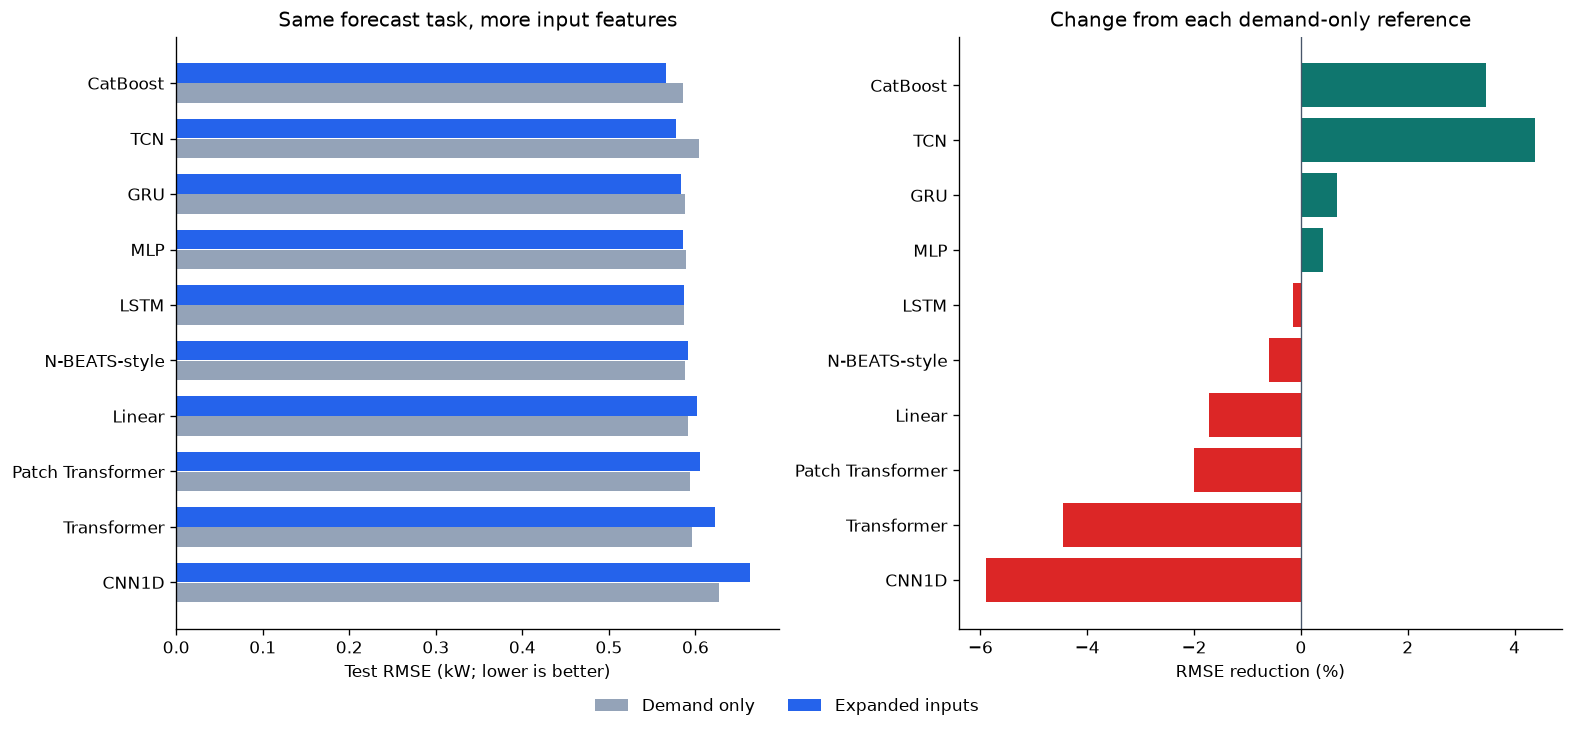

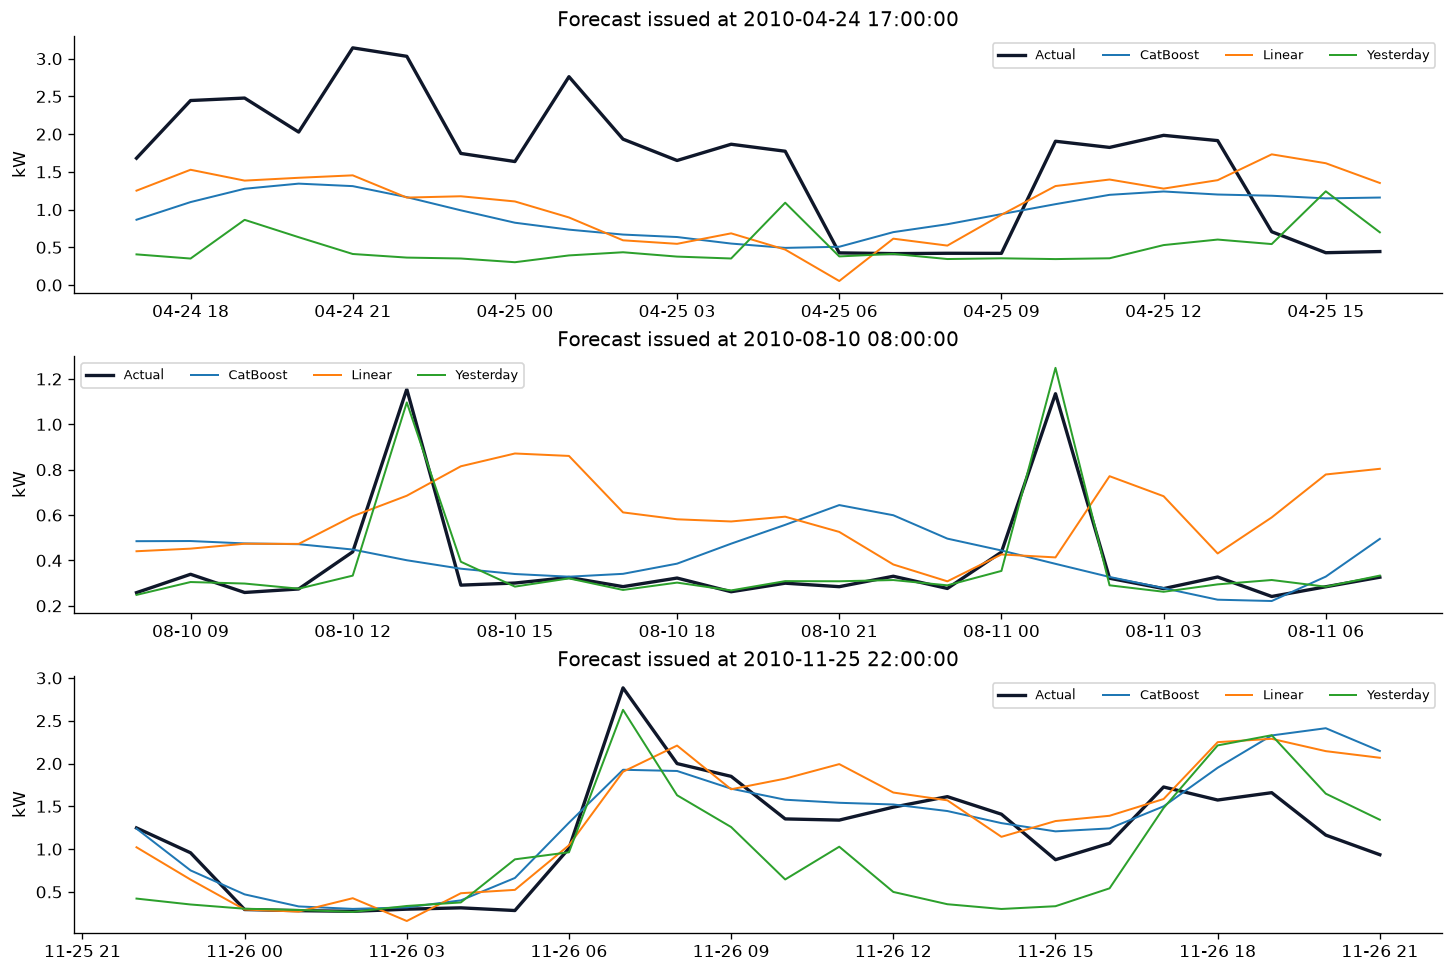

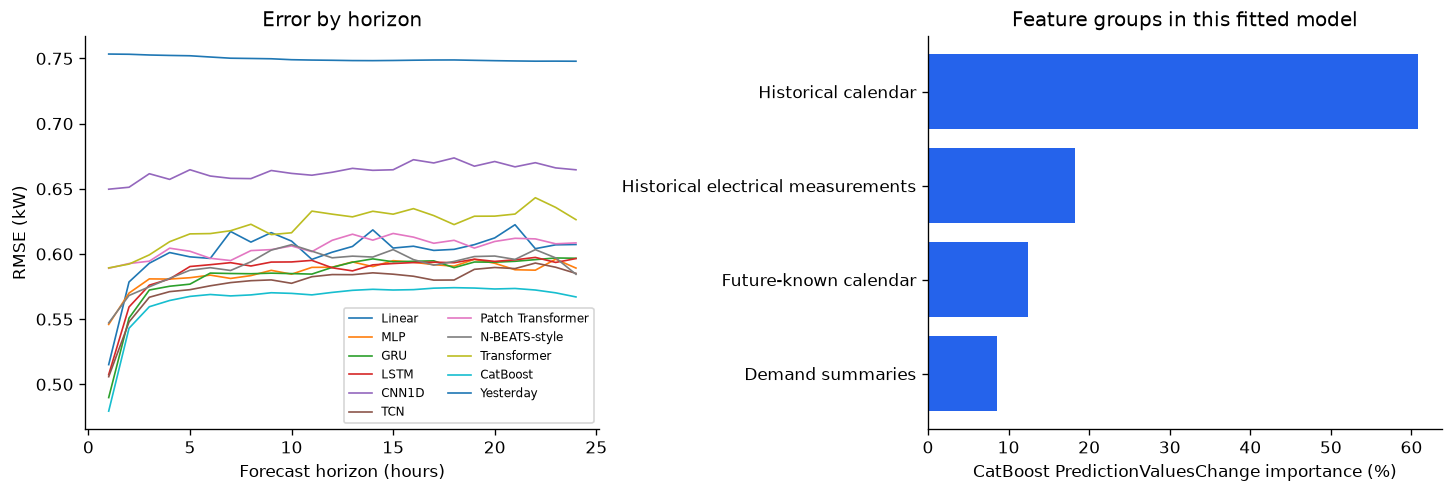

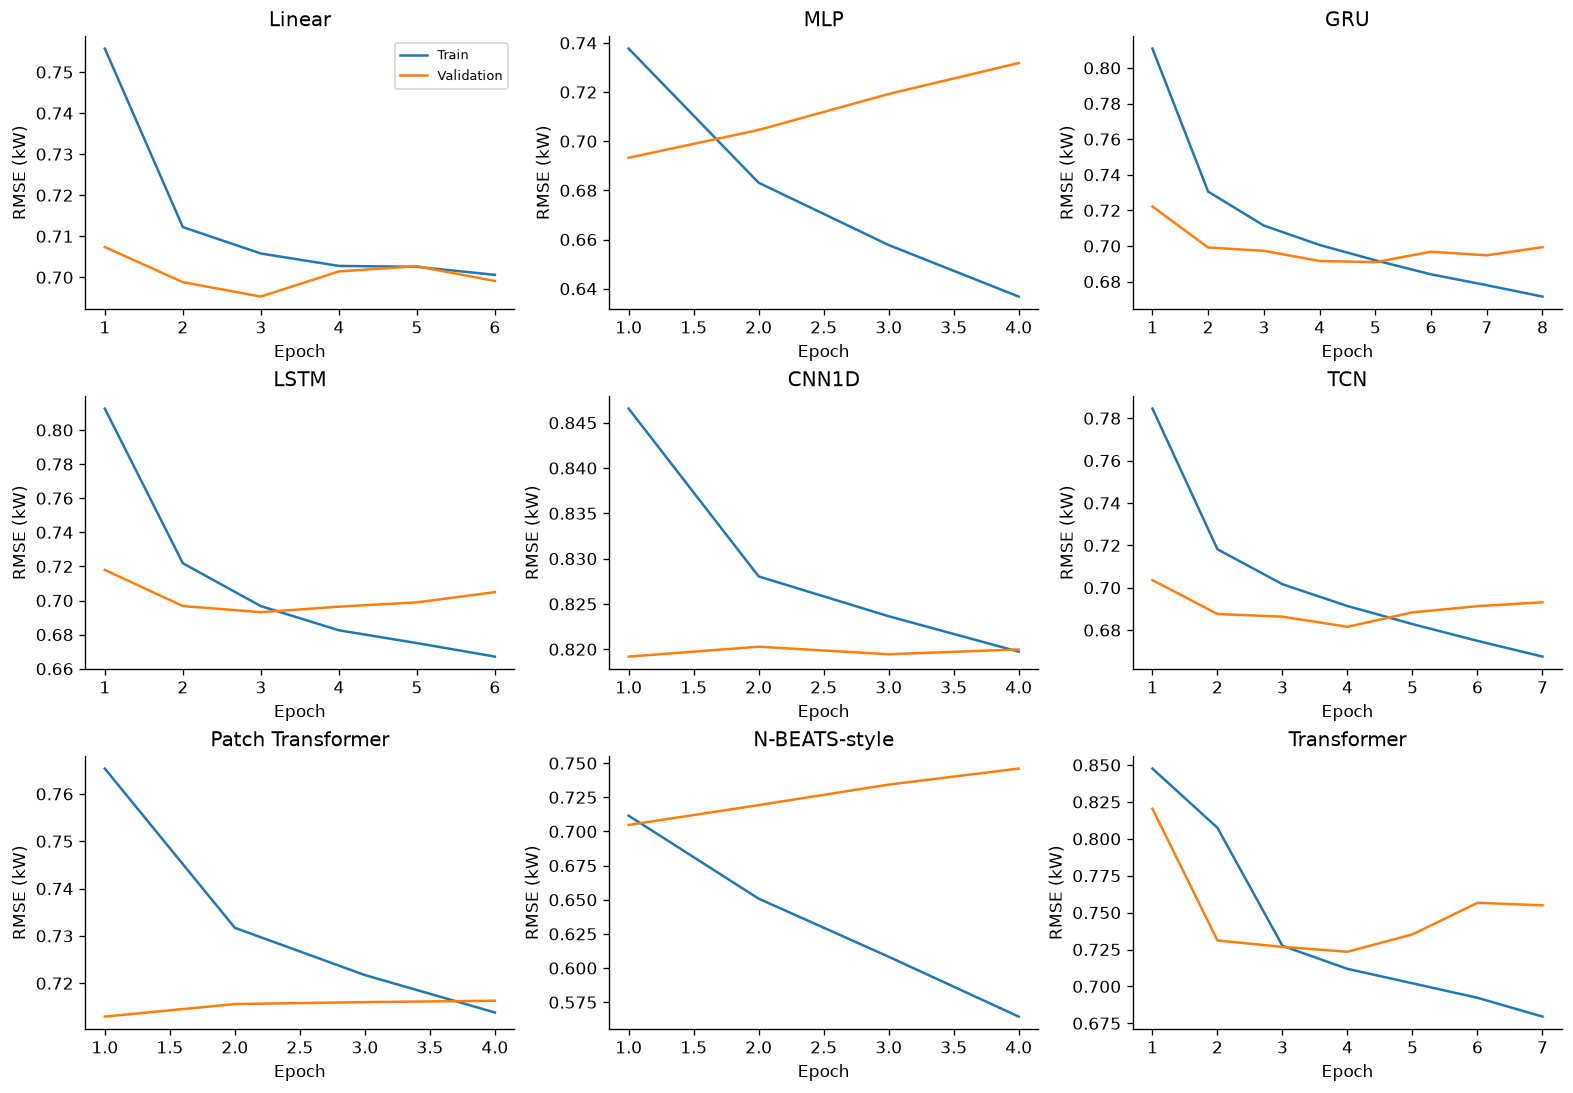

Best expanded model: CatBoost, test RMSE 0.5656 kW.
Expanded inputs improved 4 of 10 matched model configurations.
Best original neural reference: 0.5864 kW.


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6), constrained_layout=True)
chart = comparison.iloc[::-1]
ypos = np.arange(len(chart))
axes[0].barh(ypos - 0.18, chart["test_rmse_kw_demand"], height=0.35,
             label="Demand only", color="#94a3b8")
axes[0].barh(ypos + 0.18, chart["test_rmse_kw_expanded"], height=0.35,
             label="Expanded inputs", color="#2563eb")
axes[0].set(yticks=ypos, yticklabels=chart["model"], xlabel="Test RMSE (kW; lower is better)",
            title="Same forecast task, more input features")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncol=2, frameon=False)
axes[1].barh(ypos, chart["improvement_pct"],
    color=["#0f766e" if v > 0 else "#dc2626" for v in chart["improvement_pct"]])
axes[1].axvline(0, color="#475569", lw=0.8)
axes[1].set(yticks=ypos, yticklabels=chart["model"], xlabel="RMSE reduction (%)",
            title="Change from each demand-only reference")
fig.savefig(OUTPUT_DIR / "feature_comparison.png", bbox_inches="tight")
plt.show()

expanded_names = MODEL_NAMES + (["CatBoost"] if RUN_CATBOOST and FEATURE_SET == "all" else [])
best_row = results.loc[results["model"].isin(expanded_names)].iloc[0]
best_name = best_row["model"]
selected_names = list(dict.fromkeys([best_name, "Linear", "Yesterday"]))
fig, axes = plt.subplots(3, 1, figsize=(12, 8), constrained_layout=True)
for ax, offset in zip(axes, (0, len(test_origins)//2, len(test_origins)-1)):
    t = int(test_origins[offset])
    times = hourly.index[t:t+HORIZON]
    ax.plot(times, y_test_kw[offset], color="#0f172a", lw=2, label="Actual")
    for name in selected_names:
        ax.plot(times, predictions_by_model[name][offset], lw=1.2, label=name)
    ax.set(title=f"Forecast issued at {times[0]}", ylabel="kW")
    ax.legend(ncol=len(selected_names)+1, fontsize=8)
fig.savefig(OUTPUT_DIR / "forecast_examples.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for name in expanded_names + ["Yesterday"]:
    horizon_rmse = np.sqrt(np.mean((predictions_by_model[name] - y_test_kw)**2, axis=0))
    axes[0].plot(np.arange(1, HORIZON+1), horizon_rmse, label=name, lw=1)
axes[0].set(xlabel="Forecast horizon (hours)", ylabel="RMSE (kW)", title="Error by horizon")
axes[0].legend(fontsize=7, ncol=2)
if RUN_CATBOOST and FEATURE_SET == "all":
    importance = pd.read_csv(OUTPUT_DIR / "catboost_feature_importance.csv")
    grouped = importance.groupby("group")["importance"].sum().sort_values()
    axes[1].barh(grouped.index, grouped.values, color="#2563eb")
    axes[1].set(xlabel="CatBoost PredictionValuesChange importance (%)",
                title="Feature groups in this fitted model")
else:
    axes[1].axis("off")
fig.savefig(OUTPUT_DIR / "horizons_and_feature_groups.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(13, 9), constrained_layout=True)
for ax, name in zip(axes.flat, MODEL_NAMES):
    history = pd.DataFrame(histories[name])
    ax.plot(history["epoch"], history["train_rmse_kw"], label="Train")
    ax.plot(history["epoch"], history["validation_rmse_kw"], label="Validation")
    ax.set(title=name, xlabel="Epoch", ylabel="RMSE (kW)")
axes.flat[0].legend(fontsize=8)
fig.savefig(OUTPUT_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()

improved = int((comparison["improvement_pct"] > 0).sum())
best_demand_rmse = original_results.loc[original_results["kind"] == "Learned", "test_rmse_kw"].min()
print(f"Best expanded model: {best_name}, test RMSE {best_row['test_rmse_kw']:.4f} kW.")
print(f"Expanded inputs improved {improved} of {len(comparison)} matched model configurations.")
print(f"Best original neural reference: {best_demand_rmse:.4f} kW.")


## What this comparison can tell us

Compare each model with its own demand-only reference before comparing ranks.
The new bundle introduces measurements and known calendar information, and
re-expresses existing demand history with summaries. It also changes input-layer
and output-head parameter counts. A gain therefore supports this complete
configuration rather than proving that a particular architecture or sensor is
best. Some additional electrical channels closely track demand and may add little
forecasting information a day ahead.

A useful next experiment is a controlled ablation: demand only; demand plus
calendar; demand plus calendar and summaries; then the other electrical channels.
Use the same chronological split and several seeds, and select configurations on
validation data. Keep the final test set for the final comparison. CatBoost
importance describes this fitted model and is not a causal estimate of a
feature's value. More correlated or more numerous features can affect it.

## Sharing and rerunning

The embedded CSV makes this file self-contained. To host the data on GitHub,
upload `data/electricity_hourly_multifeature.csv` unchanged and set `DATA_URL`
to its public Raw URL. The older demand-only CSV does not contain the six added
electrical channels and cannot be substituted. `SOURCE_MODE = "uci"` rebuilds
the expanded CSV from the official archive, with source and processed checksums.
Retain the UCI citation and license attribution when redistributing it.

Changing the device, package versions, seed, or hyperparameters can change the
results. CPU was executed for the saved outputs; accelerator availability is
checked on the machine that runs the notebook. Training time is optional local
diagnostic information and does not appear in the main comparison.